# E-commerce Exploratory Data Analysis & Data Cleaning

## Project Overview

This project focuses on analyzing an e-commerce dataset
using Python and Pandas.

### Objectives
- Understand the dataset.
- Perform data cleaning.
- Handle missing and duplicate values.
- Analyze sales and profit.
- Identify top-performing categories.
- Explore customer purchasing patterns.
- Generate meaningful business insights.

### Technologies
- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn
- Jupyter Notebook

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import warnings

warnings.filterwarnings('ignore')

sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
# Define dataset paths
base_path = "../data/raw/"

# Load datasets
orders = pd.read_csv(base_path + "List of Orders.csv")
order_details = pd.read_csv(base_path + "Order Details.csv")
sales_target = pd.read_csv(base_path + "Sales target.csv")

print("All datasets loaded successfully!")

All datasets loaded successfully!


In [3]:
print("LIST OF ORDERS")
display(orders.head())

print("ORDER DETAILS")
display(order_details.head())

print("SALES TARGET")
display(sales_target.head())

LIST OF ORDERS


,Order ID,Order Date,CustomerName,State,City
0,B-25601,01-04-2018,Bharat,Gujarat,Ahmedabad
1,B-25602,01-04-2018,Pearl,Maharashtra,Pune
2,B-25603,03-04-2018,Jahan,Madhya Pradesh,Bhopal
3,B-25604,03-04-2018,Divsha,Rajasthan,Jaipur
4,B-25605,05-04-2018,Kasheen,West Bengal,Kolkata


ORDER DETAILS


,Order ID,Amount,Profit,Quantity,Category,Sub-Category
0,B-25601,1275.0,-1148.0,7,Furniture,Bookcases
1,B-25601,66.0,-12.0,5,Clothing,Stole
2,B-25601,8.0,-2.0,3,Clothing,Hankerchief
3,B-25601,80.0,-56.0,4,Electronics,Electronic Games
4,B-25602,168.0,-111.0,2,Electronics,Phones


SALES TARGET


,Month of Order Date,Category,Target
0,Apr-18,Furniture,10400.0
1,May-18,Furniture,10500.0
2,Jun-18,Furniture,10600.0
3,Jul-18,Furniture,10800.0
4,Aug-18,Furniture,10900.0


In [4]:
print("Orders Shape:", orders.shape)
print("Order Details Shape:", order_details.shape)
print("Sales Target Shape:", sales_target.shape)

Orders Shape: (560, 5)
Order Details Shape: (1500, 6)
Sales Target Shape: (36, 3)


In [5]:
print("ORDERS INFORMATION")
orders.info()

print("\nORDER DETAILS INFORMATION")
order_details.info()

print("\nSALES TARGET INFORMATION")
sales_target.info()

ORDERS INFORMATION
<class 'pandas.DataFrame'>
RangeIndex: 560 entries, 0 to 559
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   Order ID      500 non-null    str  
 1   Order Date    500 non-null    str  
 2   CustomerName  500 non-null    str  
 3   State         500 non-null    str  
 4   City          500 non-null    str  
dtypes: str(5)
memory usage: 22.0 KB

ORDER DETAILS INFORMATION
<class 'pandas.DataFrame'>
RangeIndex: 1500 entries, 0 to 1499
Data columns (total 6 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Order ID      1500 non-null   str    
 1   Amount        1500 non-null   float64
 2   Profit        1500 non-null   float64
 3   Quantity      1500 non-null   int64  
 4   Category      1500 non-null   str    
 5   Sub-Category  1500 non-null   str    
dtypes: float64(2), int64(1), str(3)
memory usage: 70.4 KB

SALES TARGET INFORMATION
<class 'panda

In [6]:
display(orders.describe(include="all"))
display(order_details.describe(include="all"))
display(sales_target.describe(include="all"))

,Order ID,Order Date,CustomerName,State,City
count,500,500,500,500,500
unique,500,307,332,19,24
top,B-25601,24-11-2018,Shreya,Madhya Pradesh,Indore
freq,1,7,6,101,76


,Order ID,Amount,Profit,Quantity,Category,Sub-Category
count,1500,1500.000000,1500.000000,1500.000000,1500,1500
unique,500,NaN,NaN,NaN,3,17
top,B-25656,NaN,NaN,NaN,Clothing,Saree
freq,12,NaN,NaN,NaN,949,210
mean,NaN,287.668000,15.970000,3.743333,NaN,NaN
std,NaN,461.050488,169.140565,2.184942,NaN,NaN
min,NaN,4.000000,-1981.000000,1.000000,NaN,NaN
25%,NaN,45.000000,-9.250000,2.000000,NaN,NaN
50%,NaN,118.000000,9.000000,3.000000,NaN,NaN
75%,NaN,322.000000,38.000000,5.000000,NaN,NaN


,Month of Order Date,Category,Target
count,36,36,36.000000
unique,12,3,NaN
top,Apr-18,Furniture,NaN
freq,3,12,NaN
mean,NaN,NaN,12108.333333
std,NaN,NaN,2667.837541
min,NaN,NaN,9000.000000
25%,NaN,NaN,10050.000000
50%,NaN,NaN,11450.000000
75%,NaN,NaN,14500.000000


In [7]:
datasets = {
    "Orders": orders,
    "Order Details": order_details,
    "Sales Target": sales_target
}

for name, df in datasets.items():
    print(f"\n{name}")
    print(df.isnull().sum())
    print("Total Missing:", df.isnull().sum().sum())


Orders
Order ID        60
Order Date      60
CustomerName    60
State           60
City            60
dtype: int64
Total Missing: 300

Order Details
Order ID        0
Amount          0
Profit          0
Quantity        0
Category        0
Sub-Category    0
dtype: int64
Total Missing: 0

Sales Target
Month of Order Date    0
Category               0
Target                 0
dtype: int64
Total Missing: 0


In [8]:
for name, df in datasets.items():
    print(f"{name}: {df.duplicated().sum()} duplicate rows")

Orders: 59 duplicate rows
Order Details: 0 duplicate rows
Sales Target: 0 duplicate rows


In [9]:
for name, df in datasets.items():
    print(f"\n{name}")
    display(df.dtypes)


Orders


Order ID        str
Order Date      str
CustomerName    str
State           str
City            str
dtype: object


Order Details


Order ID            str
Amount          float64
Profit          float64
Quantity          int64
Category            str
Sub-Category        str
dtype: object


Sales Target


Month of Order Date        str
Category                   str
Target                 float64
dtype: object

In [10]:
for df in [orders, order_details, sales_target]:
    for col in df.select_dtypes(include="object").columns:
        df[col] = df[col].str.strip()

In [12]:
orders["Order Date"] = pd.to_datetime(
    orders["Order Date"],
    format="%d-%m-%Y",
    errors="coerce"
)

sales_target["Month of Order Date"] = pd.to_datetime(
    sales_target["Month of Order Date"],
    format="%b-%y",
    errors="coerce"
)

In [13]:
orders = orders.drop_duplicates()
order_details = order_details.drop_duplicates()
sales_target = sales_target.drop_duplicates()

print("Duplicates removed successfully!")

Duplicates removed successfully!


In [14]:
for name, df in {
    "Orders": orders,
    "Order Details": order_details,
    "Sales Target": sales_target
}.items():
    print(f"\n{name}")
    print("Shape:", df.shape)
    print("Missing values:", df.isnull().sum().sum())
    print("Duplicates:", df.duplicated().sum())


Orders
Shape: (501, 5)
Missing values: 5
Duplicates: 0

Order Details
Shape: (1500, 6)
Missing values: 0
Duplicates: 0

Sales Target
Shape: (36, 3)
Missing values: 0
Duplicates: 0


In [15]:
merged_data = pd.merge(
    orders,
    order_details,
    on="Order ID",
    how="left"
)

display(merged_data.head())

print("Merged Dataset Shape:", merged_data.shape)

,Order ID,Order Date,CustomerName,State,City,Amount,Profit,Quantity,Category,Sub-Category
0,B-25601,2018-04-01,Bharat,Gujarat,Ahmedabad,1275.0,-1148.0,7.0,Furniture,Bookcases
1,B-25601,2018-04-01,Bharat,Gujarat,Ahmedabad,66.0,-12.0,5.0,Clothing,Stole
2,B-25601,2018-04-01,Bharat,Gujarat,Ahmedabad,8.0,-2.0,3.0,Clothing,Hankerchief
3,B-25601,2018-04-01,Bharat,Gujarat,Ahmedabad,80.0,-56.0,4.0,Electronics,Electronic Games
4,B-25602,2018-04-01,Pearl,Maharashtra,Pune,168.0,-111.0,2.0,Electronics,Phones


Merged Dataset Shape: (1501, 10)


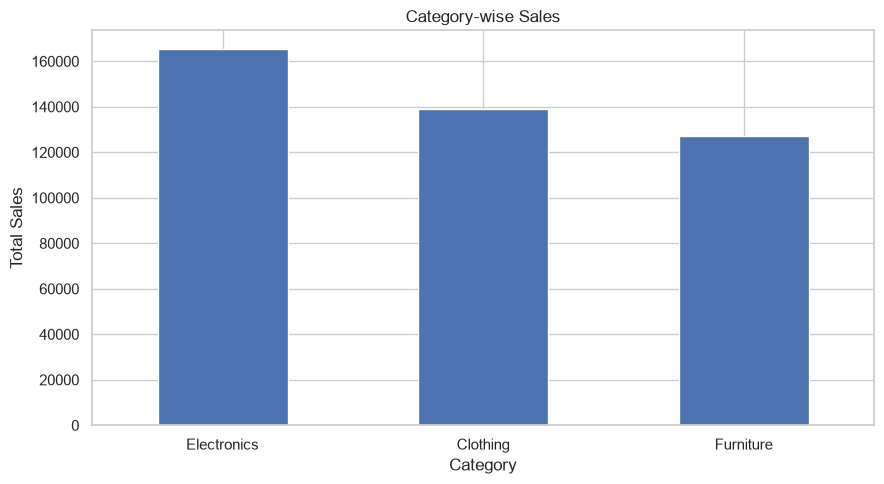

In [16]:
category_sales = merged_data.groupby(
    "Category"
)["Amount"].sum().sort_values(ascending=False)

plt.figure(figsize=(9, 5))

category_sales.plot(kind="bar")

plt.title("Category-wise Sales")
plt.xlabel("Category")
plt.ylabel("Total Sales")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

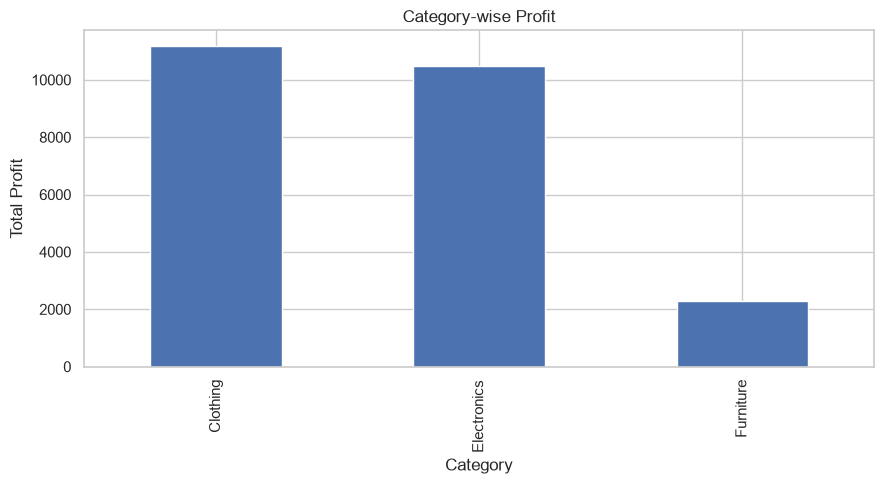

In [17]:
category_profit = merged_data.groupby(
    "Category"
)["Profit"].sum()

plt.figure(figsize=(9, 5))

category_profit.plot(kind="bar")

plt.title("Category-wise Profit")
plt.xlabel("Category")
plt.ylabel("Total Profit")

plt.tight_layout()
plt.show()

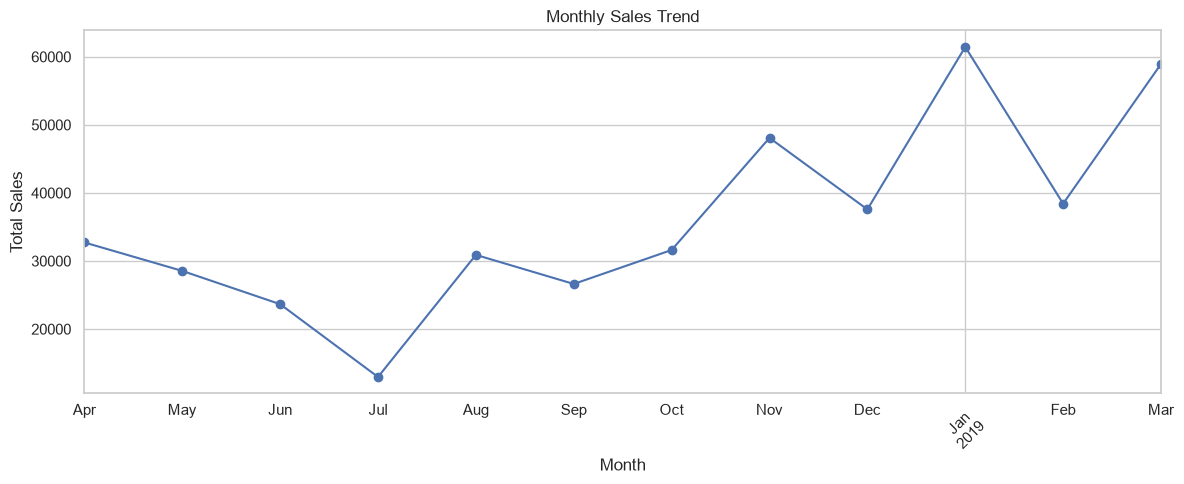

In [18]:
merged_data["Month"] = merged_data["Order Date"].dt.to_period("M")

monthly_sales = merged_data.groupby(
    "Month"
)["Amount"].sum()

plt.figure(figsize=(12, 5))

monthly_sales.plot(kind="line", marker="o")

plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [19]:
os.makedirs("../data/processed", exist_ok=True)

orders.to_csv("../data/processed/cleaned_orders.csv", index=False)

order_details.to_csv(
    "../data/processed/cleaned_order_details.csv",
    index=False
)

sales_target.to_csv(
    "../data/processed/cleaned_sales_target.csv",
    index=False
)

merged_data.to_csv(
    "../data/processed/merged_ecommerce_data.csv",
    index=False
)

print("Cleaned datasets exported successfully!")

Cleaned datasets exported successfully!
